In [8]:
import numpy as np

import math
import matplotlib.pyplot as plt
import importlib
import copy # for copying objects (like meshes!)
%matplotlib inline

import cgle  # many subroutines moved here 

notebookroot = 'CGLE_gen_'  # for output files


In [72]:
importlib.reload(cgle)  # if you are working on the helper routines 

<module 'cgle' from '/Users/aquillen/Desktop/summer25/pylab/Boundaries_F2026/cgle.py'>

### The complex Ginzburg-Landau model parameter space figs

In [88]:
def alpha_EI(beta):  # Eckhaus instability line estimate from Aranson+02
    c = beta 
    Q_E =  k_Hagan(beta)
    QE2 = Q_E*Q_E
    b = ( QE2*(3. + 2*c*c) - 1.0 ) / (c*(1.0 - QE2))
    return b

# Outer stability line by Aranson+02
def OR_line(beta):
    c = beta
    b = (c - 0.845)/((0.845+1)*c)
    return b

# Hagan 82 seems to have alpha=0, their q is our beta if alpha=0
# using equation 3.12 and 3.27
def k_Hagan(beta):
    gm = 0.5772 # Euler const
    C_1 = -0.098
    q = (beta  + 1e-6)
    k = (2/q) * np.exp(-np.pi/(2*q) - gm)
    return k

if (1==0):
    beta = np.linspace(0.0,5,101)
    kbeta = k_Hagan(beta)
    fig,ax = plt.subplots(1,1,figsize=(3,3))
    ax.plot(beta,kbeta,'-')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel('k (Hagan82)')
    plt.show()

 alpha=2.00 beta =-0.75
 alpha=2.00 beta =-1.00
 alpha=0.00 beta =-1.79
 alpha=2.00 beta =-0.20


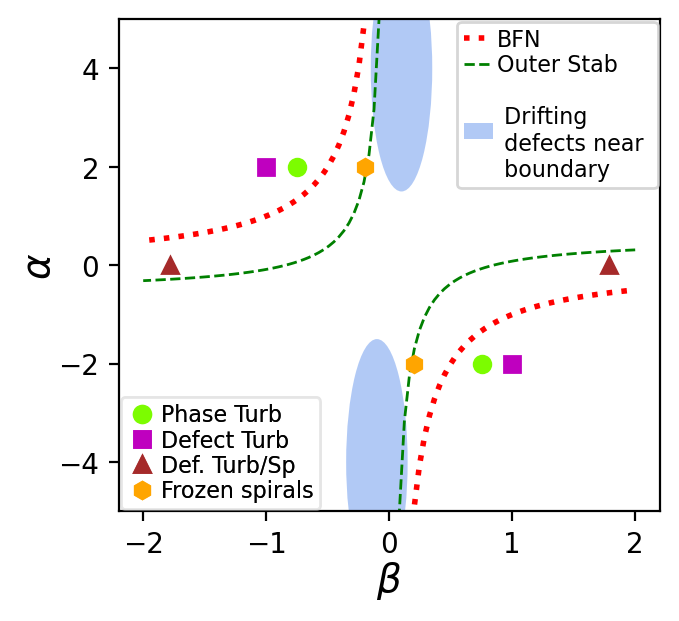

In [116]:
# create a figure showing regimes for the CGLE
fig,ax = plt.subplots(1,1,figsize=(3.3,3.0), dpi=200)
plt.subplots_adjust(left=0.16,bottom=0.16,right=0.98,top=0.98)
alpha = np.linspace(-5,5,100)
beta = np.linspace(0.001,2,50)
ax.set_ylim([-5,5])
#ax.text( 1.5,-3,'unstable',ha='center',va='center')
#ax.text(-1.5, 3,'unstable',ha='center',va='center')
ax.set_ylabel(r'$\alpha$',fontsize=14,labelpad=0.1)
ax.set_xlabel(r'$\beta$',fontsize=14,labelpad=0.1)

y = -1/beta  # BFN line # Benjamin-Feir-Newell instability line up to which one has convectively stable plane-wave solutions
#a_EI = alpha_EI(beta)  # attempt at Eckhaus instability line
#ax.plot(beta,a_EI, 'b-', lw=1,label='EI')
#ax.plot(-beta,-a_EI, 'b-', lw=1)
l1,=ax.plot(beta,y, 'r:',label='BFN',lw=2)
ax.plot(-beta,-y, 'r:',lw=2)
a_OR = OR_line(beta) # outer instability for spiral stability
l2,=ax.plot(beta,a_OR, 'g--',lw=1,label='Outer Stab')
ax.plot(-beta,-a_OR, 'g--',lw=1)

# points are taken from Chate and Manneville 1996 review article
alpha,beta = cgle.Chate_to_Aranson(2,1.33)
p1,=ax.plot(beta,alpha,'o',label='Phase Turb',color='lawngreen')
ax.plot(-beta,-alpha,'o',color='lawngreen')
#alpha,beta = cgle.Chate_to_Aranson(2,1.28)
#ax.plot(beta,alpha,'bo',label='Phase Turb')
#ax.plot(-beta,-alpha,'bo')
alpha,beta = cgle.Chate_to_Aranson(2,1)
p2,=ax.plot(beta,alpha,'ms',label='Defect Turb')
ax.plot(-beta,-alpha,'ms')
alpha,beta = cgle.Chate_to_Aranson(0,0.56)
p3,=ax.plot(beta,alpha,'^',label='Def. Turb/Sp', color='brown')
ax.plot(-beta,-alpha,'^', color='brown')
alpha,beta = cgle.Chate_to_Aranson(2,5)
p4,=ax.plot(beta,alpha,'h',label='Frozen spirals', color='orange')
ax.plot(-beta,-alpha,'h', color='orange')
#alpha,beta = cgle.Chate_to_Aranson(2,1.67)
#ax.plot(beta,alpha,'h',label='Frozen spirals', color='orange')

from matplotlib.patches import Ellipse

ell = Ellipse(xy=(0.1,4),width=0.5, height=5,angle=0,facecolor='cornflowerblue',alpha=0.5,label='\n Drifting \n defects near \n boundary')
ell2 = Ellipse(xy=(-0.1,-4),width=0.5, height=5,angle=0,facecolor='cornflowerblue',alpha=0.5)
#ell.set_facecolor('red')
ell.set_clip_box(ax.bbox)
ell2.set_clip_box(ax.bbox)
ee1 = ax.add_artist(ell)
ax.add_artist(ell2)

first_legend = ax.legend(handles=[l1,l2,ee1], loc='upper right', \
                         fontsize=8,borderpad=0.3,labelspacing=0.1,handlelength=1.3,handletextpad=0.2,borderaxespad=0.1)
second_legend = ax.legend(handles=[p1,p2,p3,p4], loc='lower left', \
                         fontsize=8,borderpad=0.3,labelspacing=0.1,handlelength=1.3,handletextpad=0.2,borderaxespad=0.1,framealpha=0.3)
#ax.legend(fontsize=8,borderpad=0.3,labelspacing=0.1,handlelength=1.3,handletextpad=0.2,borderaxespad=0.1,loc='lower left')
ax.add_artist(first_legend)
ax.add_artist(second_legend)

plt.savefig(notebookroot+'space.png')
plt.show()

the relation for Eckhaus is
$ \frac{ (1+bc)}{(3 + 2c^2 + bc)} = Q_E^2 $
I invert this to give 
$ b =  \frac{ Q_E^2 ( 3  + 2c^2) - 1 }{ c ( 1- Q_E^2)} $
Now put it in terms of our $\alpha, \beta$ 
giving 
$ \alpha =  \frac{ Q_E^2 ( 3  + 2\beta^2) - 1 }{ \beta ( 1- Q_E^2)} $
and we use the above relation for $Q_E = k_\text{Hagan}$? 

In [120]:
#alpha beta A_b,Static, Defects, Periodic 
beh_AB11 = np.array(\
[[6,  0.8 , 1.1 , -1  ,  1 ,  1 ], 
[6 ,  0.4 , 1.1 , -1  ,  1 ,  1 ],
[6 ,  0.2 , 1.1 , -1  ,  1 ,  1 ],
[6 ,  0.0 , 1.1 , -1  ,  1 , -1 ],
[6 , -0.2 , 1.1 , -1  ,  1 , -1 ],
[6 , -0.5 , 1.1 ,  1  , -1 , -1 ],
[3 ,  0.8 , 1.1 , -1  ,  1 ,  1 ],
[3 ,  0.4 , 1.1 , -1  ,  1 ,  1 ],
[3 ,  0.2 , 1.1 , -1  ,  1 ,  1 ],
[3 , -0.1 , 1.1 , -1  ,  1 , -1 ],
[3 , -0.3 , 1.1 ,  1  , -1 , -1 ],
[1 ,  0.2 , 1.1 , -1  ,  1 ,  1 ],
[1 ,  0.1 , 1.1 , -1  ,  1 ,  1 ],
[1 ,  0.0 , 1.1 , -1  ,  1 , -1 ],
[1 , -0.1 , 1.1 ,  1 ,  -1 , -1 ]])
# behavior for boundary -1.1


#alpha beta A_b,Static, Defects, Periodic 
beh_AB5 = np.array(\
[[6,  0.2 , 0.5 , -1  ,  1 ,  1 ],
[6 ,  0.0 , 0.5 , -1  ,  1 ,  1 ],
[6 , -0.1 , 0.5 , -1  ,  1 , -1 ],
[6 , -0.2 , 0.5 , -1  ,  1 , -1 ],
[6 , -0.4 , 0.5 , -1  ,  1 , -1 ],
[6 , -0.8 , 0.5 , -1  ,  1 , -1 ],
[3 ,  0.2 , 0.5 , -1  ,  1 ,  1 ],
[3 ,  0.0 , 0.5 , -1  ,  1 ,  1 ],
[3 , -0.1 , 0.5 , -1  ,  1 , -1 ],
[3 , -0.3 , 0.5 , -1  ,  1 , -1 ],
[3 , -0.6 , 0.5 ,  1  , -1 , -1 ],
[1 ,  0.1 , 0.5 , -1  ,  1 ,  1 ],
[1 ,  0.0 , 0.5 , -1  ,  1 ,  1 ],
[1 , -0.05, 0.5 , -1  ,  1 , -2 ],
[1 , -0.1 , 0.5 ,  1  , -1 , -1 ],
[1 , -0.2 , 0.5 ,  1  , -1 , -1 ]])
# behavior for boundary -0.5


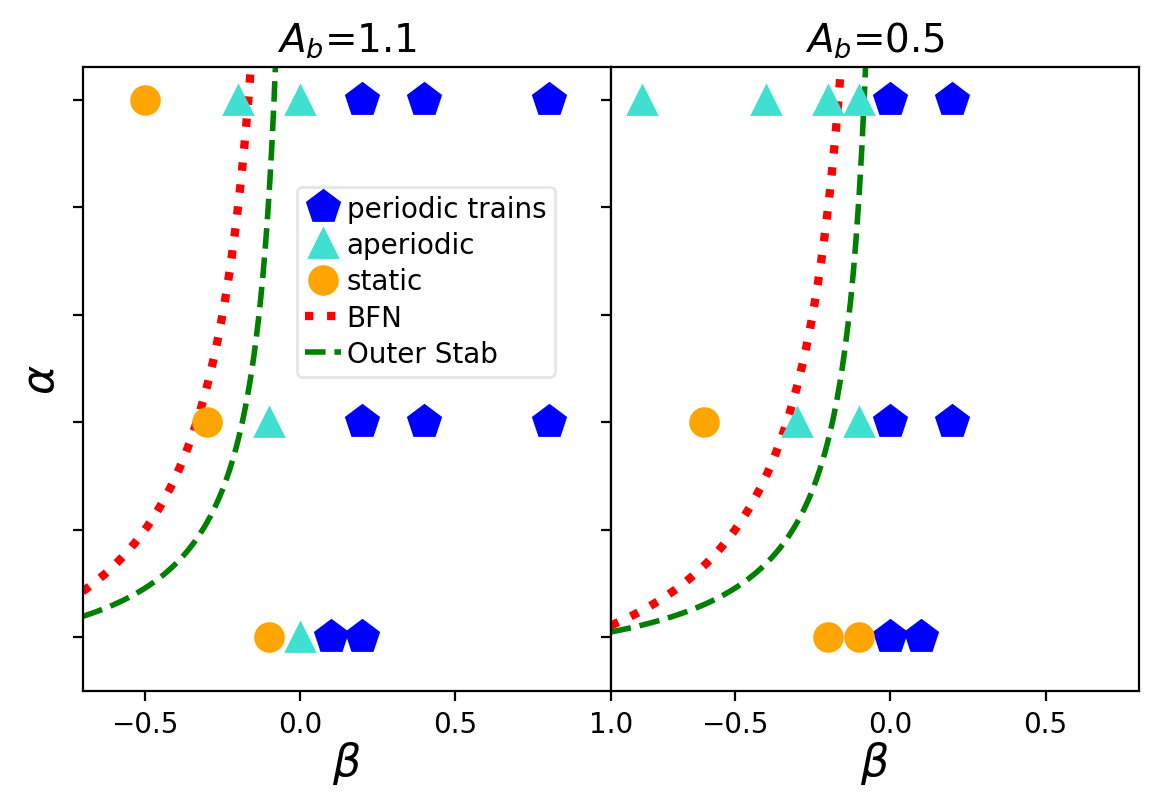

In [154]:
def psubs(data,fig,ax,leg=True):
    alpha = data[:,0]  # is alpha
    beta = data[:,1]  
    A_b  = data[:,2]  
    static = data[:,3]  
    defects = data[:,4]  
    periodic = data[:,5]  
    ii = (periodic >0)
    mms = 10
    ax.plot(beta[ii],alpha[ii],'bp', label='periodic trains',ms=mms+2,zorder=4)

    ii = np.logical_and((periodic ==-1),defects>0)
    ax.plot(beta[ii],alpha[ii],'^', label='aperiodic',color='turquoise',ms=mms,zorder=4)
    
    ii = (static >0)
    ax.plot(beta[ii],alpha[ii],'o', label='static',color='orange',ms=mms,zorder=4)

    [b1,b2] = ax.get_xlim()
    #[a1,a2] = ax.get_ylim()
    
    blin = np.linspace(b1,-0.0001,100)
    BFN_line = -1/blin 
    #ax.plot(-blin,-BFN_line,':')
    ax.plot(blin,BFN_line,'r:',label='BFN',lw=3,zorder=2)
    a_OR = OR_line(blin) # outer instability for spiral stability
    ax.plot(blin,a_OR,'g--',label='Outer Stab',lw=2,zorder=2)
    
    if (leg==True):
        ax.legend(fontsize=10,borderpad=0.3,labelspacing=0.3,handlelength=1.3,handletextpad=0.2,borderaxespad=0.1,framealpha=0.5,\
                  bbox_to_anchor=(0.4, 0.5, 0.5, 0.5))  # x,y, width,height
         #    loc='lower left')


def show_beh2(data1,data2,ofile=''):
     
    fig,axarr = plt.subplots(1,2,figsize=(6,4),dpi=200,sharey=True)
    plt.subplots_adjust(bottom=0.15,left=0.10,top=0.93,right=0.98,hspace=0,wspace=0)

    ax0 = axarr[0]; ax1=axarr[1]
    ax1.set_ylim([0.5,6.3])
    ax0.set_ylabel(r'$\alpha$',labelpad=0.1,fontsize=16)
    ax0.set_xlabel(r'$\beta$',labelpad=0.1,fontsize=16)
    ax1.set_xlabel(r'$\beta$',labelpad=0.1,fontsize=16)
    #ax1.set_yticklabels([]) 
    ax1.set(yticklabels=[]) 
    ax0.set_xlim([-0.7,-0.7+1.7])
    ax1.set_xlim([-0.9,-0.9+1.7])

    label0=r'$A_b$=1.1'
    ax0.set_title(label0,fontsize=14)
    label1=r'$A_b$=0.5'
    ax1.set_title(label1,fontsize=14)

    psubs(data1,fig,ax0)
    psubs(data2,fig,ax1,leg=False)
    

    if (len(ofile)>3):
        plt.savefig(ofile)
    plt.show()

show_beh2(beh_AB11,beh_AB5,ofile=notebookroot+'beh.png')

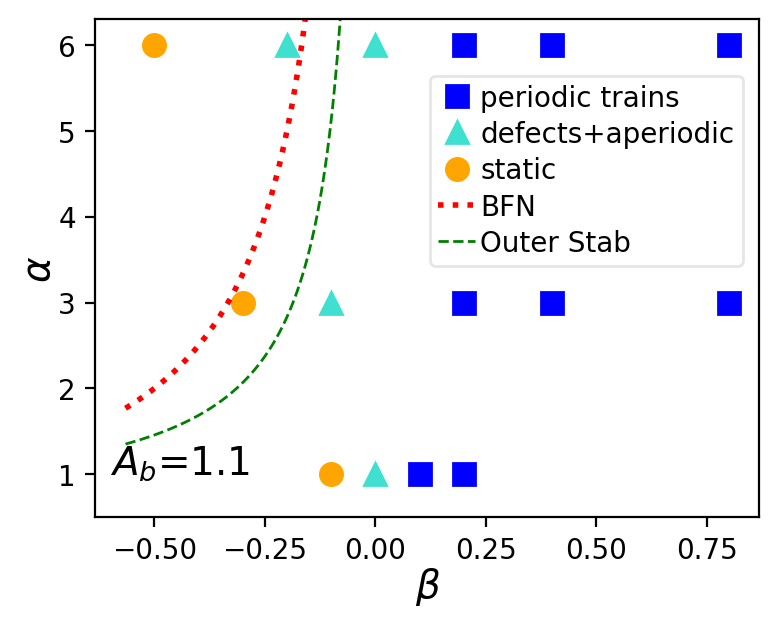

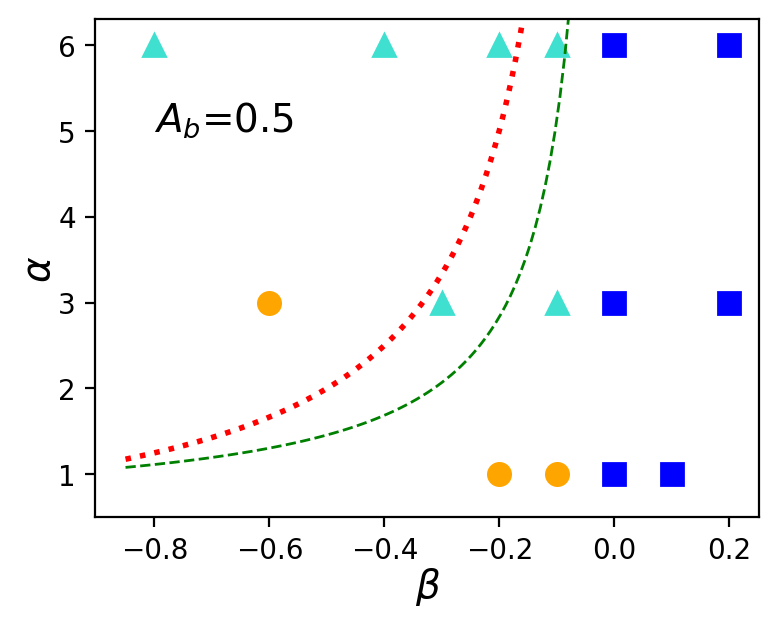

In [114]:
def show_beh(junk,label='',labelpos=(0,0),leg=True,ofile=''):
    alpha = junk[:,0]  # is alpha
    beta = junk[:,1]  
    A_b  = junk[:,2]  
    static = junk[:,3]  
    defects = junk[:,4]  
    periodic = junk[:,5]  
    
    fig,ax = plt.subplots(1,1,figsize=(4,3),dpi=200)
    plt.subplots_adjust(bottom=0.15,left=0.15,top=0.98,right=0.98)
    ax.set_ylabel(r'$\alpha$',labelpad=0.1,fontsize=14)
    ax.set_xlabel(r'$\beta$',labelpad=0.1,fontsize=14)
    ax.text(labelpos[0],labelpos[1],label,fontsize=14)
    
    ii = (periodic >0)
    ax.plot(beta[ii],alpha[ii],'bp', label='periodic trains',ms=8)

    ii = np.logical_and((periodic ==-1),defects>0)
    ax.plot(beta[ii],alpha[ii],'^', label='defects+aperiodic',color='turquoise',ms=8)
    
    ii = (static >0)
    ax.plot(beta[ii],alpha[ii],'o', label='static',color='orange',ms=8)

    [b1,b2] = ax.get_xlim()
    #[a1,a2] = ax.get_ylim()
    ax.set_ylim([0.5,6.3])
    blin = np.linspace(b1,-0.0001,100)
    BFN_line = -1/blin 
    #ax.plot(-blin,-BFN_line,':')
    ax.plot(blin,BFN_line,'r:',label='BFN',lw=2)
    a_OR = OR_line(blin) # outer instability for spiral stability
    ax.plot(blin,a_OR,'g--',label='Outer Stab',lw=1)

    if (leg==True):
        ax.legend(fontsize=10,borderpad=0.3,labelspacing=0.3,handlelength=1.3,handletextpad=0.2,borderaxespad=0.1,framealpha=0.5,\
                  bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))  # x,y, wdith,hgith
         #    loc='lower left')

    if (len(ofile)>3):
        plt.savefig(ofile)
    plt.show()

show_beh(beh_AB11,label=r'$A_b$=1.1',labelpos = (-0.6,1.),leg=True,ofile=notebookroot+'beh11.png')
show_beh(beh_AB5,label=r'$A_b$=0.5',labelpos = (-0.8,5),leg=False,ofile=notebookroot+'beh5.png')

In [112]:
4*np.pi/55

0.2284794657156213

In [74]:
np.linspace(0,1,100)

array([0.        , 0.01010101, 0.02020202, 0.03030303, 0.04040404,
       0.05050505, 0.06060606, 0.07070707, 0.08080808, 0.09090909,
       0.1010101 , 0.11111111, 0.12121212, 0.13131313, 0.14141414,
       0.15151515, 0.16161616, 0.17171717, 0.18181818, 0.19191919,
       0.2020202 , 0.21212121, 0.22222222, 0.23232323, 0.24242424,
       0.25252525, 0.26262626, 0.27272727, 0.28282828, 0.29292929,
       0.3030303 , 0.31313131, 0.32323232, 0.33333333, 0.34343434,
       0.35353535, 0.36363636, 0.37373737, 0.38383838, 0.39393939,
       0.4040404 , 0.41414141, 0.42424242, 0.43434343, 0.44444444,
       0.45454545, 0.46464646, 0.47474747, 0.48484848, 0.49494949,
       0.50505051, 0.51515152, 0.52525253, 0.53535354, 0.54545455,
       0.55555556, 0.56565657, 0.57575758, 0.58585859, 0.5959596 ,
       0.60606061, 0.61616162, 0.62626263, 0.63636364, 0.64646465,
       0.65656566, 0.66666667, 0.67676768, 0.68686869, 0.6969697 ,
       0.70707071, 0.71717172, 0.72727273, 0.73737374, 0.74747